# Hydrological Data

,Date,Segment_id,x,y,Evapotranspiration,Precipitation,Irrigation_pumping,Observed,DateTime
0,710732,144,1086190,14476800,0.59,18.99,0.0,0.145161,1945-12-02
1,710763,144,1086190,14476800,0.97,29.63,0.0,0.445161,1946-01-02
2,710791,144,1086190,14476800,1.34,29.63,0.0,1.332203,1946-01-30
3,710822,144,1086190,14476800,1.79,29.63,0.0,2.932203,1946-03-02
4,710852,144,1086190,14476800,8.23,29.63,0.0,3.728689,1946-04-01


<Axes: xlabel='x', ylabel='y'>

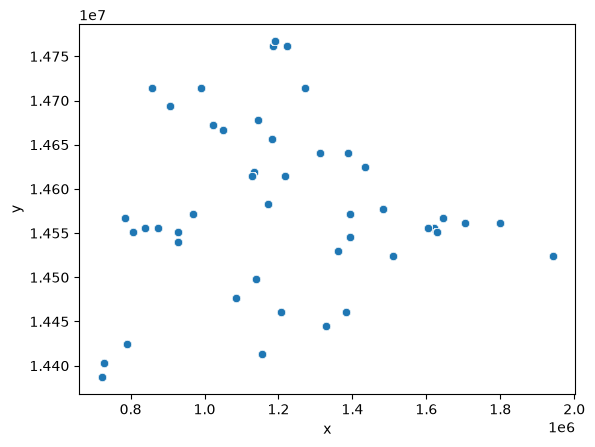

In [41]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('data/RRCA_baseflow.csv')
# Date is days since 1/1/0000
df['DateTime'] = pd.to_datetime(df['Date'], unit='D', origin='0000-1-1')

display(df.head(5))

segments = df.copy()
segments.drop_duplicates(subset=['Segment_id'], keep='first')
segments

sns.scatterplot(data=segments, x='x', y='y')

Presumably the correlations will be a bit different for each segment. I wonder how/if you can account for that. Do we just have to leave out segment? Maybe there's a consistent relationship as x or y increases by I kinda doubt it.

It seems like the river branches out as you go left (idk whether it's a delta or those are tributaries). Either way `x` could be a meaningful feature. I doubt `y` would have any significant correlation.

min 1939-10-02 00:00:00 max 2000-09-01 00:00:00
Number of segments: 42


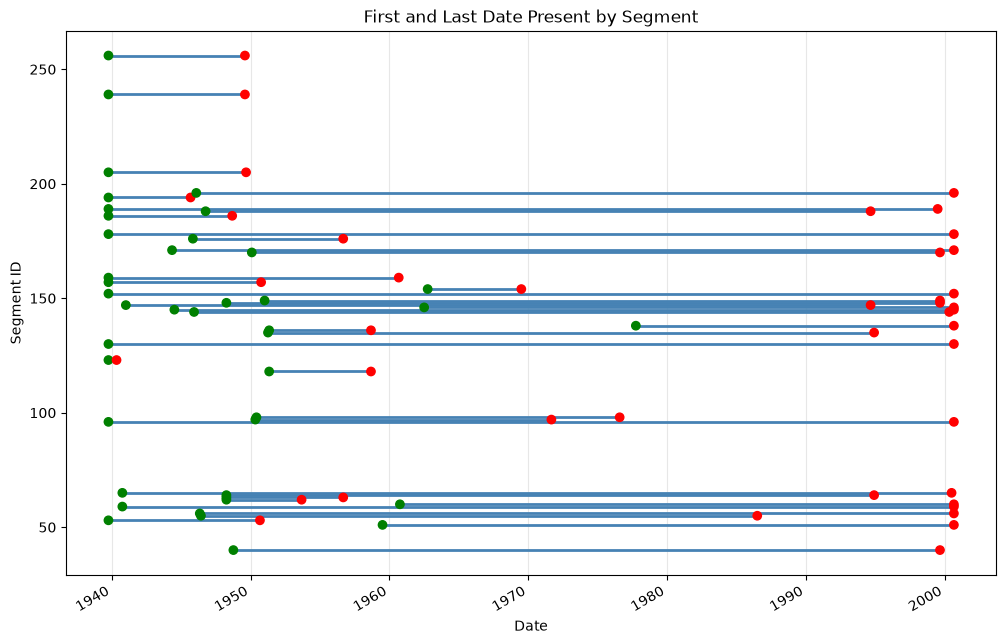

In [42]:
# Date range
print(f'min {df['DateTime'].min()} max {df['DateTime'].max()}')

# Research events during time range
num_segments = df['Segment_id'].nunique()
print(f'Number of segments: {num_segments}')
df['Segment_id'].value_counts(normalize=True)
# df[df['Segment_id'] == 123]
date_ranges = (
    df.groupby('Segment_id')['DateTime']
      .agg(first='min', last='max')
      .sort_values('first')
)

fig, ax = plt.subplots(figsize=(12, 8))

for segment_id, row in date_ranges.iterrows():
    ax.plot([row['first'], row['last']], [segment_id, segment_id],
            color='steelblue', linewidth=2)
    ax.scatter([row['first'], row['last']], [segment_id, segment_id],
               color=['green', 'red'], zorder=3)

ax.set_xlabel('Date')
ax.set_ylabel('Segment ID')
ax.set_title('First and Last Date Present by Segment')
ax.grid(axis='x', alpha=0.3)
fig.autofmt_xdate()
plt.show()

In [43]:
# location_summary = (
#     multi_location.groupby(["Segment_id", "x", "y"], dropna=False)
#     .agg(
#         first_reading=("DateTime", "min"),
#         last_reading=("DateTime", "max"),
#         row_count=("Segment_id", "size"),
#     )
#     .reset_index()
# )

# location_summary = (
#     location_summary
#     .merge(
#         location_counts,
#         on=["Segment_id", "x", "y"],
#         how="left",
#     )
#     .sort_values(["Segment_id", "x", "y"])
# )

# display(location_summary)


Where/When is this?
Dates: 10/2/1939 - 9/1/2000

Republican River Basin - a 15.9-million-acre watershed spanning northeastern Colorado, southwestern Nebraska, and northwestern Kansas

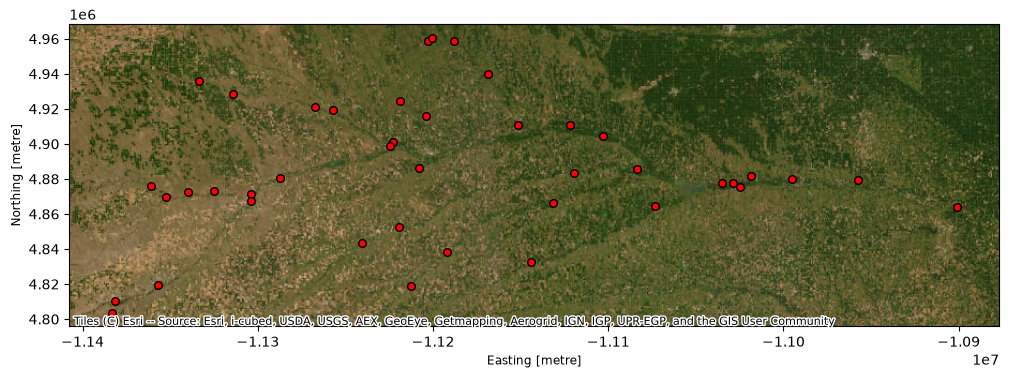

dict_keys(['WorldStreetMap', 'WorldTopoMap', 'WorldImagery', 'WorldTerrain', 'WorldShadedRelief', 'WorldPhysical', 'OceanBasemap', 'NatGeoWorldMap', 'WorldGrayCanvas', 'ArcticImagery', 'ArcticOceanBase', 'ArcticOceanReference', 'AntarcticImagery', 'AntarcticBasemap'])


In [44]:
import geopandas as gpd, contextily as cx, matplotlib.pyplot as plt

segments = df.drop_duplicates("Segment_id")
gdf = gpd.GeoDataFrame(segments, geometry=gpd.points_from_xy(segments.x * 0.3048, segments.y * 0.3048),
                       crs="EPSG:26914").to_crs(epsg=3857)   # UTM 14 (ft -> m) -> web mercator
ax = gdf.plot(figsize=(12, 6), color="red", markersize=30, edgecolor="k")
cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery)  # or cx.providers.Esri.WorldImagery
plt.show()

print(cx.providers.Esri.keys())

### Screen for Segments With Bad Data
Check if any segments have their precip, evapotranspiration, or pumping set to 0 for most of their rows.

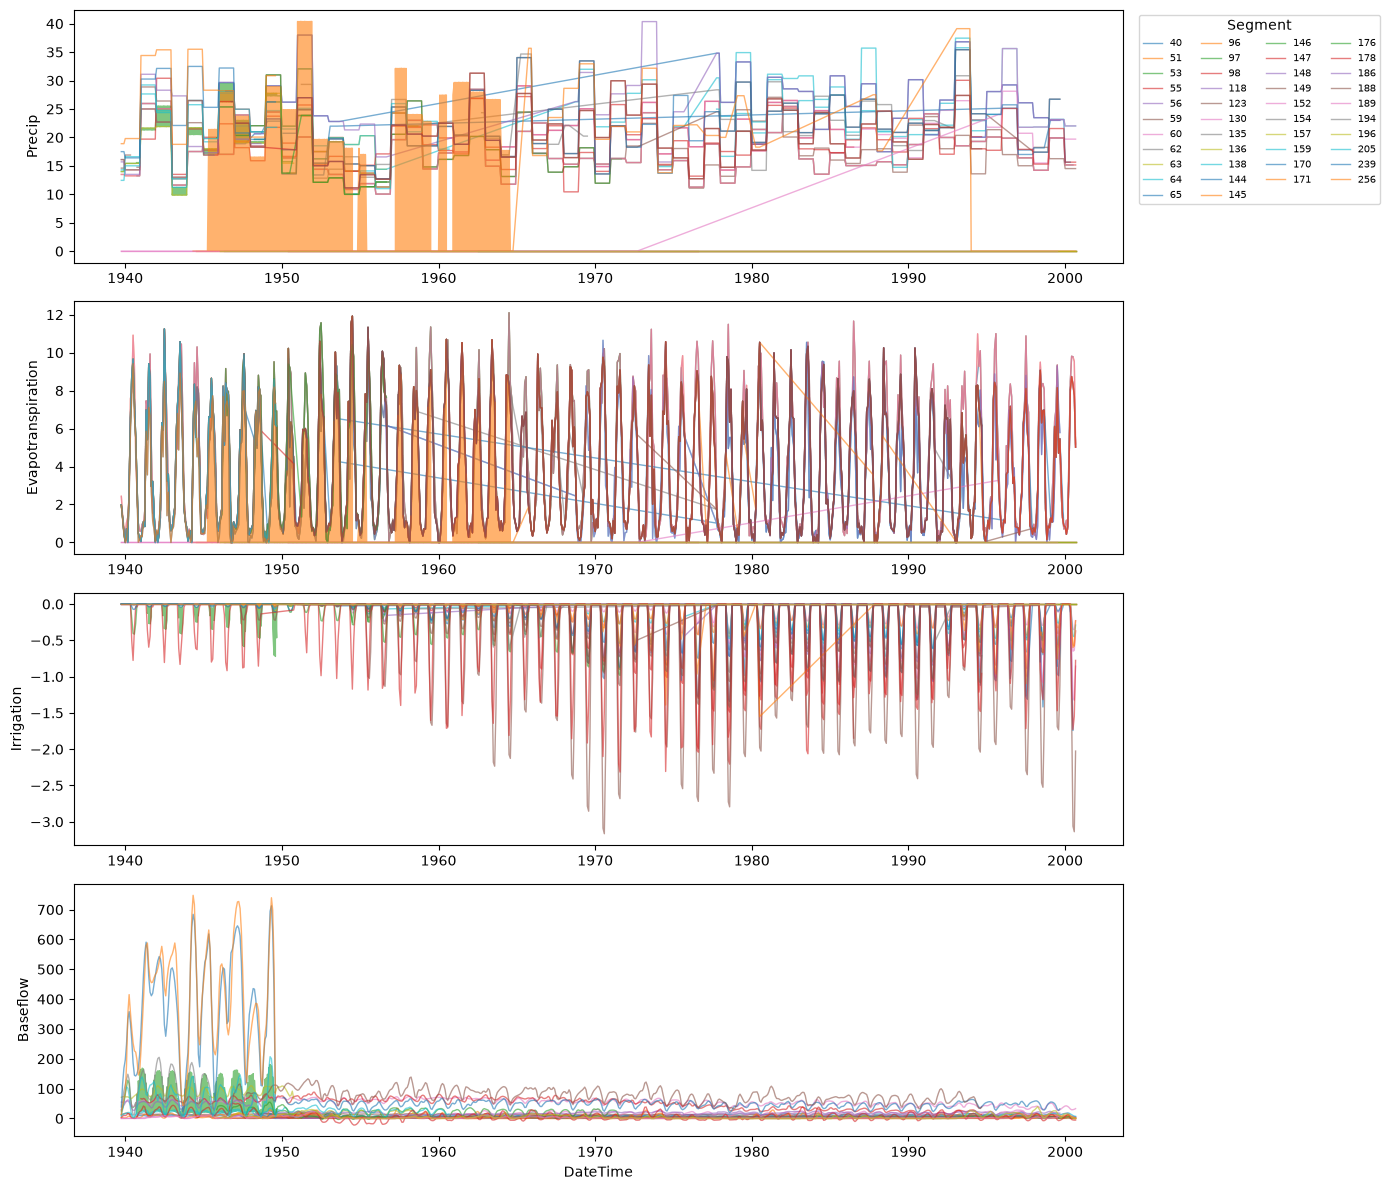

In [45]:
sorted = df.sort_values('DateTime')

fig, axes = plt.subplots(4, 1, figsize=(14,12))
for seg_id, group in sorted.groupby('Segment_id'):
    axes[0].plot(group['DateTime'], group['Precipitation'], label=seg_id, linewidth=1, alpha=0.6)
    axes[1].plot(group['DateTime'], group['Evapotranspiration'], label=seg_id, linewidth=1, alpha=0.6)
    axes[2].plot(group['DateTime'], group['Irrigation_pumping'], label=seg_id, linewidth=1, alpha=0.6)
    axes[3].plot(group['DateTime'], group['Observed'], label=seg_id, linewidth=1, alpha=0.6)

axes[3].set_xlabel('DateTime')
axes[0].set_ylabel('Precip')
axes[1].set_ylabel('Evapotranspiration')
axes[2].set_ylabel('Irrigation')
axes[3].set_ylabel('Baseflow')

axes[0].legend(title="Segment", ncol=4, fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")

plt.tight_layout()
plt.show()

In [ ]:
# Solid color shows segments with multiple coordinates.
# Place all those readings into a separate segment id.
df['Segment_id'] = df['Segment_id'].astype(str)
locs = df[['Segment_id', 'x', 'y']].drop_duplicates().copy()
locs['n'] = locs.groupby('Segment_id').cumcount()
locs['new_id'] = locs['Segment_id'] + locs['n'].map(
    lambda n: '' if n == 0 else chr(ord("A") + n - 1)
)
df = df.merge(locs[["Segment_id", "x", "y", "new_id"]],
              on=["Segment_id", "x", "y"], how="left")
df["seg_key"] = df.pop("new_id")

# seg_key is segment_id with a letter tacked onto it if it's a different set of coordinates for a segment_id

### Individual Linear Regression Models